In [1]:
import sys
RE_path = './'
sys.path.insert(1, RE_path)


In [2]:
import numpy as np
from matplotlib import pyplot as plt
import RE
import importlib
importlib.reload(RE)
from RE import *
import RESolver as solver
importlib.reload(solver)
import scipy.constants as const

# Example Solution using SPARC-like Parameters #

In [32]:
def getj0(I0,nx):
    r = np.linspace(0,1,nx)
    jp0 = 13.3e6 * (1-r**2)**0.5 # A/m**2
    javg = 2 * np.pi * np.trapz(jp0*r,x=r) / (np.pi * 1**2) # average jinit
    rmax = np.sqrt(I0 / (javg * np.pi)) # radius required to preserve total current
    return jp0, rmax

# Constants
R0 = 1.85 # [m]
a = 0.57 # [m]
Zeff = 1
T = 5 # eV
ne = 3e21 # per m**3
lnA = 15
eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
    
# Initial Conditions
jp0, rmax = getj0(8.7e6,128)
jr0 = np.zeros_like(jp0)

constants = [rmax, R0, ne, T, Zeff, lnA, eta]
init_conditions = [jp0, jr0]

Configure the solver

In [27]:
import RESolver as solver
importlib.reload(solver)

out = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=10e-3,
                        CFL=0.5,
                        RE_sources=[1,1,1,1], # [iDreicer, iTritBeta, iCompton, iAvalanche]
                        cre=0.1*3e8,
                        nprint=500,
                        verbose=True)



nx = 128

I0 [MA] = 8.71

Ir (t = 0) [MA] = 0

iDreicer = 1,iTritBeta = 1, iCompton = 1, iAvalanche = 1

Runaway Velocity [m/s]= 3e+07

Time Step dt [ms] = 0.000173

Seed Ir(t=dt) [MA] = 0.311

step = 500, time [ms] = 0.09, Ip [MA] = 7.37, E/Ec [-] = 1897.63
step = 1000, time [ms] = 0.17, Ip [MA] = 6.70, E/Ec [-] = 1256.87
step = 1500, time [ms] = 0.26, Ip [MA] = 6.28, E/Ec [-] = 763.50
step = 2000, time [ms] = 0.35, Ip [MA] = 6.01, E/Ec [-] = 445.45
step = 2500, time [ms] = 0.43, Ip [MA] = 5.85, E/Ec [-] = 253.95
step = 3000, time [ms] = 0.52, Ip [MA] = 5.75, E/Ec [-] = 142.70
step = 3500, time [ms] = 0.60, Ip [MA] = 5.70, E/Ec [-] = 79.49
step = 4000, time [ms] = 0.69, Ip [MA] = 5.67, E/Ec [-] = 44.13
step = 4500, time [ms] = 0.78, Ip [MA] = 5.65, E/Ec [-] = 24.55
step = 5000, time [ms] = 0.86, Ip [MA] = 5.64, E/Ec [-] = 13.77
step = 5500, time [ms] = 0.95, Ip [MA] = 5.64, E/Ec [-] = 7.86
step = 6000, time [ms] = 1.04, Ip [MA] = 5.63, E/Ec [-] = 4.63
step = 6500, time [ms] = 1.12, Ip

Show results

(0.0, 9.14079498765389)

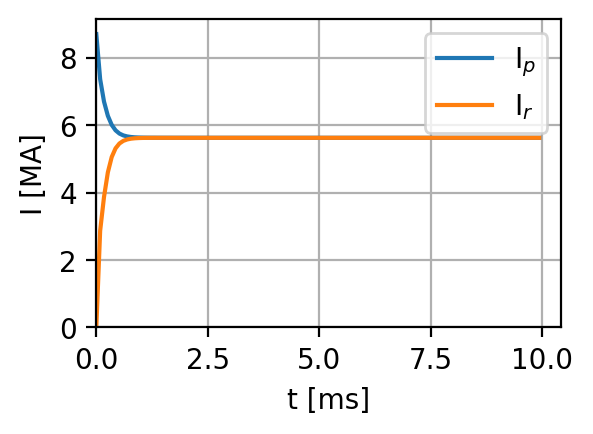

In [28]:
# Show Results
t, Ip, Ir = np.array(out['t']), np.array(out['Ip']), np.array(out['Ir'])
fig, axs = plt.subplots(1, 1, figsize=(3,2), dpi=200, sharex=True)

axs.plot(t * 1e3, Ip / 1e6, label='I$_p$')
axs.plot(t * 1e3, Ir / 1e6, label='I$_r$')
axs.set_xlabel('t [ms]')
axs.set_ylabel('I [MA]')
axs.grid()
axs.legend()
axs.set_xlim(xmin=0)
axs.set_ylim(ymin=0)



Final Profile

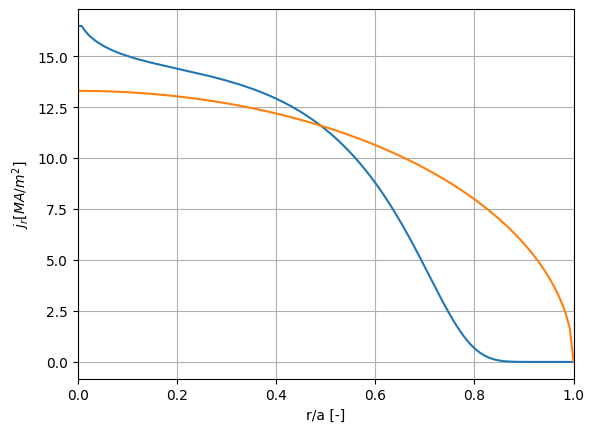

In [29]:
r = np.linspace(0,rmax,out['jr'].shape[0])

plt.plot(r/rmax,out['jr']/1e6)
plt.plot(r/rmax,jp0/1e6)
plt.xlabel('r/a [-]')
plt.ylabel('$j_r [MA/m^2]$')
plt.xlim([0,1])
plt.grid()

### With REs Turned on - Dreicer Source

nx = 128

I0 [MA] = 8.71

Ir (t = 0) [MA] = 0

iDreicer = 1,iTritBeta = 0, iCompton = 0, iAvalanche = 1

Runaway Velocity [m/s]= 3e+07

Time Step dt [ms] = 3.45e-05

Seed Ir(t=dt) [MA] = 0.0621

step = 2500, time [ms] = 0.09, Ip [MA] = 7.37, E/Ec [-] = 1898.36
step = 5000, time [ms] = 0.17, Ip [MA] = 6.70, E/Ec [-] = 1257.76
step = 7500, time [ms] = 0.26, Ip [MA] = 6.28, E/Ec [-] = 764.33
step = 10000, time [ms] = 0.35, Ip [MA] = 6.01, E/Ec [-] = 446.11
step = 12500, time [ms] = 0.43, Ip [MA] = 5.85, E/Ec [-] = 254.44
step = 15000, time [ms] = 0.52, Ip [MA] = 5.75, E/Ec [-] = 143.04
step = 17500, time [ms] = 0.60, Ip [MA] = 5.70, E/Ec [-] = 79.71
step = 20000, time [ms] = 0.69, Ip [MA] = 5.67, E/Ec [-] = 44.27
step = 22500, time [ms] = 0.78, Ip [MA] = 5.65, E/Ec [-] = 24.63
step = 25000, time [ms] = 0.86, Ip [MA] = 5.64, E/Ec [-] = 13.82
step = 27500, time [ms] = 0.95, Ip [MA] = 5.64, E/Ec [-] = 7.90
step = 30000, time [ms] = 1.04, Ip [MA] = 5.63, E/Ec [-] = 4.65
step = 32500, time [ms

(0.0, 9.14079498765389)

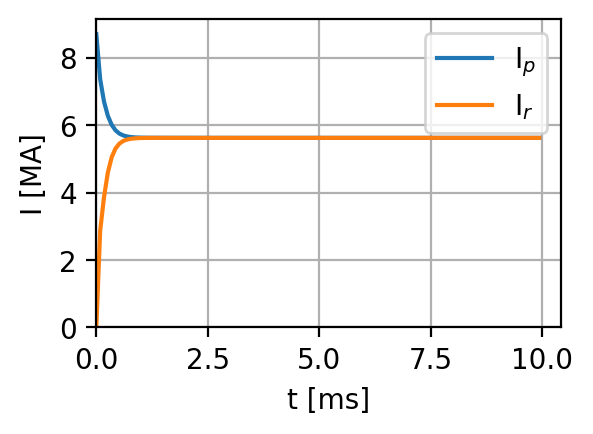

In [30]:
out = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=10e-3,
                        CFL=0.1,
                        RE_sources=[1,0,0,1],
                        cre=0.1*3e8,
                        nprint=2500,
                        verbose=True)

# Show Results
t, Ip, Ir = np.array(out['t']), np.array(out['Ip']), np.array(out['Ir'])
fig, axs = plt.subplots(1, 1, figsize=(3,2), dpi=200, sharex=True)

axs.plot(t * 1e3, Ip / 1e6, label='I$_p$')
axs.plot(t * 1e3, Ir / 1e6, label='I$_r$')
axs.set_xlabel('t [ms]')
axs.set_ylabel('I [MA]')
axs.grid()
axs.legend()
axs.set_xlim(xmin=0)
axs.set_ylim(ymin=0)

# With Activated Sources only

nx = 128

I0 [MA] = 8.71

Ir (t = 0) [MA] = 0

iDreicer = 0,iTritBeta = 1, iCompton = 1, iAvalanche = 1

Runaway Velocity [m/s]= 3e+07

Time Step dt [ms] = 0.000138

Seed Ir(t=dt) [MA] = 3.55e-13

step = 5000, time [ms] = 0.69, Ip [MA] = 3.62, E/Ec [-] = 2566.57
step = 10000, time [ms] = 1.38, Ip [MA] = 1.76, E/Ec [-] = 1273.68
step = 15000, time [ms] = 2.07, Ip [MA] = 0.86, E/Ec [-] = 622.19
step = 20000, time [ms] = 2.76, Ip [MA] = 0.42, E/Ec [-] = 303.71
step = 25000, time [ms] = 3.45, Ip [MA] = 0.20, E/Ec [-] = 148.25
step = 30000, time [ms] = 4.15, Ip [MA] = 0.10, E/Ec [-] = 72.36
step = 35000, time [ms] = 4.84, Ip [MA] = 0.05, E/Ec [-] = 35.32
step = 40000, time [ms] = 5.53, Ip [MA] = 0.02, E/Ec [-] = 17.24
step = 45000, time [ms] = 6.22, Ip [MA] = 0.01, E/Ec [-] = 8.42
step = 50000, time [ms] = 6.91, Ip [MA] = 0.01, E/Ec [-] = 4.11
step = 55000, time [ms] = 7.60, Ip [MA] = 0.00, E/Ec [-] = 2.00
step = 60000, time [ms] = 8.29, Ip [MA] = 0.00, E/Ec [-] = 0.98
step = 65000, time [m

(0.0, 9.14079498765389)

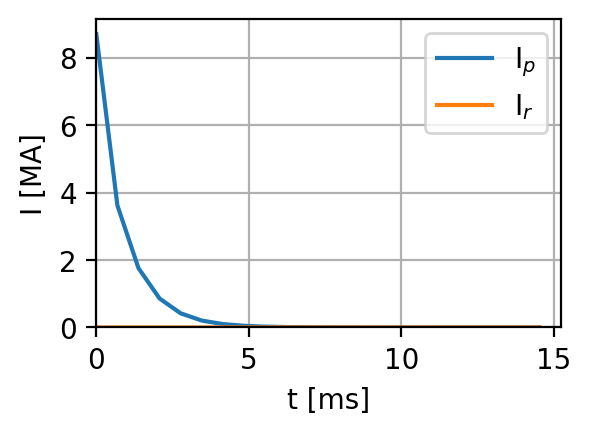

In [31]:
out = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=15e-3,
                        CFL=0.4,
                        RE_sources=[0,1,1,1],
                        cre=0.1*3e8,
                        nprint=5000,
                        verbose=True)

# Show Results
t, Ip, Ir = np.array(out['t']), np.array(out['Ip']), np.array(out['Ir'])
fig, axs = plt.subplots(1, 1, figsize=(3,2), dpi=200, sharex=True)

axs.plot(t * 1e3, Ip / 1e6, label='I$_p$')
axs.plot(t * 1e3, Ir / 1e6, label='I$_r$')
axs.set_xlabel('t [ms]')
axs.set_ylabel('I [MA]')
axs.grid()
axs.legend()
axs.set_xlim(xmin=0)
axs.set_ylim(ymin=0)
# axs.set_yscale('log')

# Trying to match NIMROD + DREAM simulations

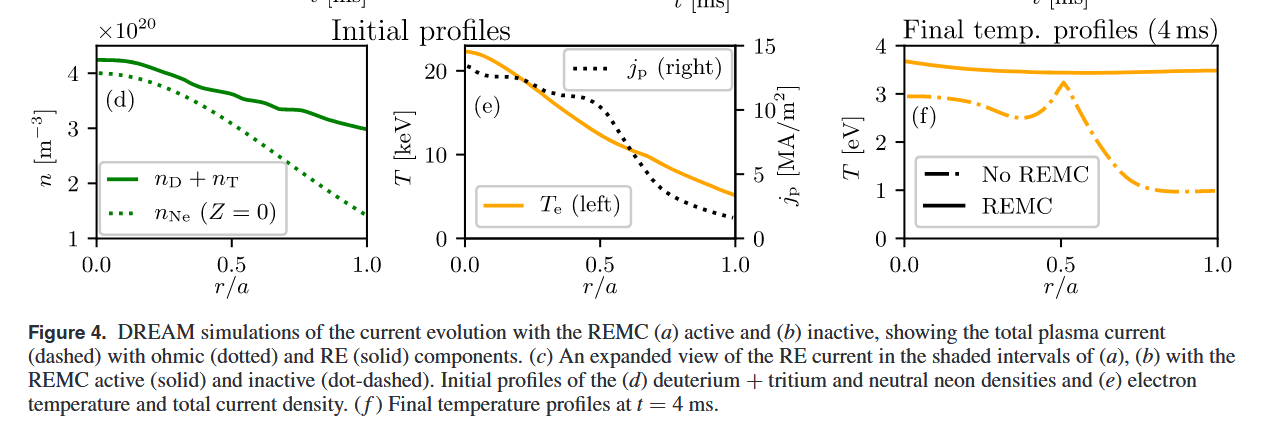

In [20]:
def getj0(I0,nx):
    r = np.linspace(0,1,nx)
    jp0 = 13.3e6 * (1-r**2)**0.7 # A/m**2
    javg = 2 * np.pi * np.trapz(jp0*r,x=r) / (np.pi * 1**2) # average jinit
    rmax = np.sqrt(I0 / (javg * np.pi)) # radius required to preserve total current
    return jp0, rmax

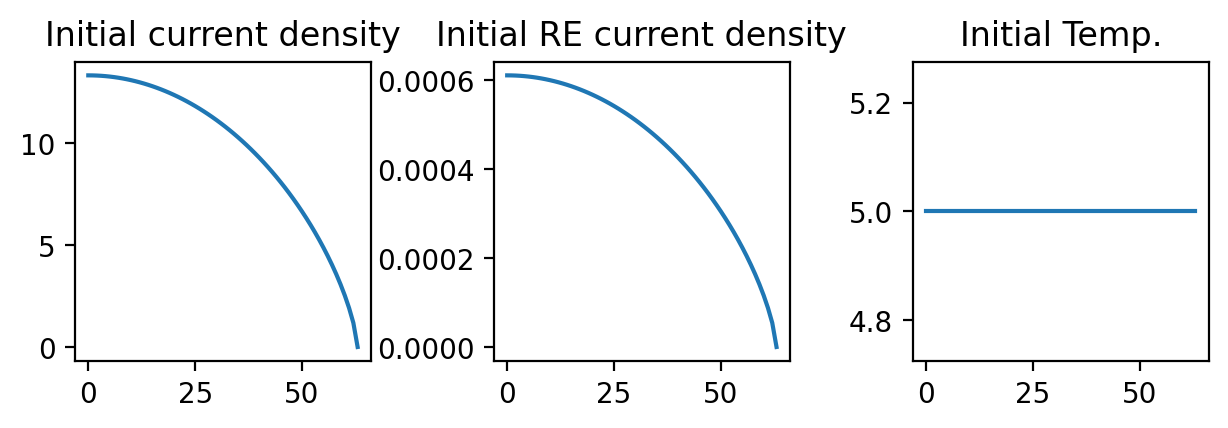

In [21]:
# Initial Conditions
jp0, rmax = getj0(8.7e6,64)
jr0 = 0.2 * jp0 * 2e3 / 8.7e6

# Constants
R0 = 1.87 # [m]
a = 0.57 * 1 # [m]
Zeff = 2
T = 5 * np.ones_like(jp0) # eV
ne = 6e20 # per m**3
lnA = 15
eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
    


constants = [rmax, R0, ne, T, Zeff, lnA, eta]
init_conditions = [jp0, jr0]

# Show Initial conditions
fig, axs = plt.subplots(1,3,figsize=(6,2),dpi=200)
axs[0].plot(jp0/1e6)
axs[0].set_title('Initial current density')
axs[1].plot(jr0/1e6)
axs[1].set_title('Initial RE current density')
axs[2].plot(T)
axs[2].set_title('Initial Temp.')

fig.tight_layout(pad=0.2)

In [33]:
import RESolver as solver
importlib.reload(solver)

out = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=2e-3,
                        CFL=0.1,
                        RE_sources=[0,0,1,1],
                        cre=0.1*3e8,
                        nprint=50,
                        verbose=False,
                        RE_start=0)



nx = 128

I0 [MA] = 8.71

Ir (t = 0) [MA] = 0

iDreicer = 0,iTritBeta = 1, iCompton = 1, iAvalanche = 1

Runaway Velocity [m/s]= 3e+07

Time Step dt [ms] = 3.45e-05

Seed Ir(t=dt) [MA] = 7.98e-13



(0.0, 9.14079498765389)

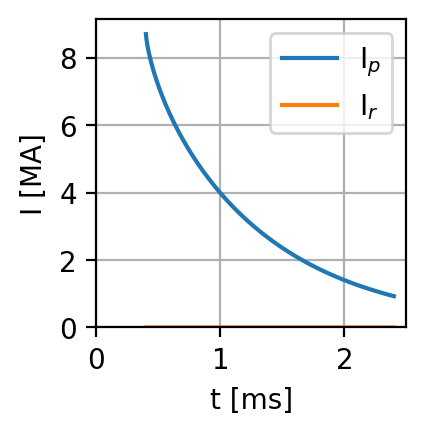

In [34]:
# Show Results
t, Ip, Ir = np.array(out['t']), np.array(out['Ip']), np.array(out['Ir'])
fig, axs = plt.subplots(1, 1, figsize=(2,2), dpi=200, sharex=True)

axs.plot(t * 1e3 + 0.4, Ip / 1e6, label='I$_p$')
axs.plot(t * 1e3 + 0.4, Ir / 1e6, label='I$_r$')
axs.set_xlabel('t [ms]')
axs.set_ylabel('I [MA]')
axs.grid()
axs.legend()
axs.set_xlim(xmin=0)
axs.set_ylim(ymin=0)



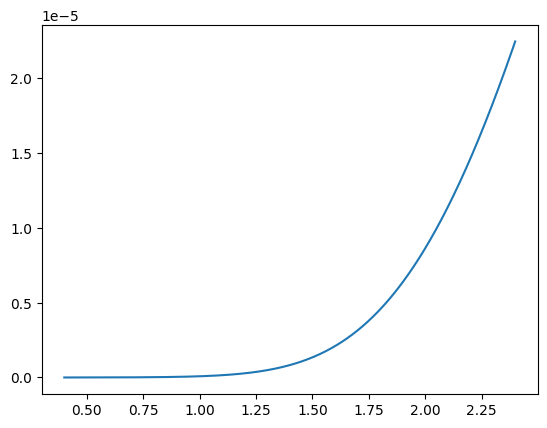

In [35]:
plt.plot(t * 1e3 + 0.4, Ir / 1e6, label='I$_r$')